# PRAKTIKUM DATA MINING
## Tugas 4 — Studi Kasus Mandiri: Kedai Kopi "Kopi Kenangan Senja"

- **Mata Kuliah**: Praktikum Data Mining
- **Topik**: Penerapan End-to-End Market Basket Analysis pada Dataset Transaksi Usaha F&B Mandiri
- **Dataset**: 50 Transaksi Kedai Kopi Modern (`coffee_shop_transactions.csv`)
- **Referensi Modul**: *Modul Praktikum Data Mining — Bagian 5.4 (Tugas 4)*


---
## Persiapan Pustaka Pendukung
Mengimpor pustaka analisis data (`pandas`, `numpy`, `matplotlib.pyplot`) dan machine learning pattern mining (`mlxtend`) agar notebook ini mandiri (*self-contained*).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

print('Pustaka pendukung berhasil diimpor siap digunakan.')


Pustaka pendukung berhasil diimpor siap digunakan.


---
# TUGAS 4 — Studi Kasus Mandiri: Kedai Kopi "Kopi Kenangan Senja"

### 4.1 Profil Dataset Mandiri
- **Bidang Usaha**: Food & Beverage (F&B) / Kedai Kopi Modern.
- **Jumlah Transaksi**: 50 transaksi struk pesanan (memenuhi syarat minimal $\ge 40$).
- **Jumlah Item**: 10 varian menu (memenuhi syarat minimal $\ge 8$): *Espresso, Americano, Kopi Susu Aren, Matcha Latte, Croissant Butter, Toast Kaya, Muffin Cokelat, Red Velvet Cake, Sandwich Tuna, Air Mineral*.


In [2]:
# Membaca dataset studi kasus mandiri
df_cs_raw = pd.read_csv('coffee_shop_transactions.csv')
cs_tx = [x.split(', ') for x in df_cs_raw['Items'].dropna()]

print(f"Jumlah transaksi studi kasus : {len(cs_tx)}")
print("\n5 Struk Transaksi Teratas:")
for i, t in enumerate(cs_tx[:5], 1):
    print(f"T{i}: {t}")

# Hitung frekuensi menu
cnt_cs = Counter()
for t in cs_tx: cnt_cs.update(t)
print(f"\nTotal jenis item menu: {len(cnt_cs)}")
for item, freq in cnt_cs.most_common():
    print(f"{item:20s}: {freq:2d} kali (support = {freq/len(cs_tx):.2f})")


Jumlah transaksi studi kasus : 50

5 Struk Transaksi Teratas:
T1: ['Espresso', 'Air Mineral']
T2: ['Espresso', 'Air Mineral']
T3: ['Espresso', 'Air Mineral']
T4: ['Kopi Susu Aren', 'Croissant Butter']
T5: ['Kopi Susu Aren', 'Croissant Butter', 'Muffin Cokelat']

Total jenis item menu: 10
Croissant Butter    : 22 kali (support = 0.44)
Air Mineral         : 18 kali (support = 0.36)
Kopi Susu Aren      : 17 kali (support = 0.34)
Espresso            : 12 kali (support = 0.24)
Americano           : 11 kali (support = 0.22)
Sandwich Tuna       : 10 kali (support = 0.20)
Muffin Cokelat      :  9 kali (support = 0.18)
Matcha Latte        :  9 kali (support = 0.18)
Red Velvet Cake     :  8 kali (support = 0.16)
Toast Kaya          :  7 kali (support = 0.14)


### 4.2 Pipeline Lengkap Association Rule Mining pada Dataset Mandiri

In [3]:
# 1. One-Hot Encoding
te_cs = TransactionEncoder()
te_cs_ary = te_cs.fit(cs_tx).transform(cs_tx)
df_cs_onehot = pd.DataFrame(te_cs_ary, columns=te_cs.columns_)

# 2. Penentuan Threshold & Eksekusi Apriori
# Alasan: min_support = 0.15 (minimal muncul pada 7-8 transaksi) agar pola kemunculan menu cukup representatif.
# min_confidence = 0.50 agar aturan memiliki kepastian pembelian minimal 50%.
fi_cs = apriori(df_cs_onehot, min_support=0.15, use_colnames=True)
fi_cs = fi_cs.sort_values('support', ascending=False).reset_index(drop=True)

# 3. Pembentukan Aturan Asosiasi
rules_cs = association_rules(fi_cs, metric='confidence', min_threshold=0.5)
rules_cs = rules_cs.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"Frequent itemsets yang ditemukan : {len(fi_cs)}")
print(f"Aturan asosiasi yang terbentuk   : {len(rules_cs)}")
cols_cs = ['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']
display(rules_cs[cols_cs].round(3))


Frequent itemsets yang ditemukan : 13
Aturan asosiasi yang terbentuk   : 8


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,frozenset({Matcha Latte}),frozenset({Red Velvet Cake}),0.16,0.889,5.556,0.131,7.56
1,frozenset({Red Velvet Cake}),frozenset({Matcha Latte}),0.16,1.000,5.556,0.131,inf
2,frozenset({Sandwich Tuna}),frozenset({Americano}),0.20,1.000,4.545,0.156,inf
3,frozenset({Americano}),frozenset({Sandwich Tuna}),0.20,0.909,4.545,0.156,8.80
4,frozenset({Air Mineral}),frozenset({Espresso}),0.24,0.667,2.778,0.154,2.28
5,frozenset({Espresso}),frozenset({Air Mineral}),0.24,1.000,2.778,0.154,inf
6,frozenset({Croissant Butter}),frozenset({Kopi Susu Aren}),0.32,0.727,2.139,0.170,2.42
7,frozenset({Kopi Susu Aren}),frozenset({Croissant Butter}),0.32,0.941,2.139,0.170,9.52


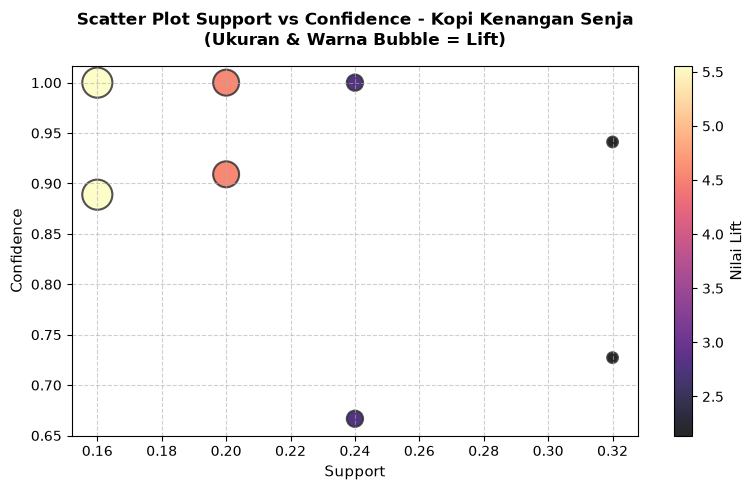

In [4]:
# Visualisasi Scatter Plot Support vs Confidence - Kedai Kopi
plt.figure(figsize=(8, 5))
sizes_cs = (rules_cs['lift'] - rules_cs['lift'].min() + 0.5) * 120
sc_cs = plt.scatter(rules_cs['support'], rules_cs['confidence'], s=sizes_cs, c=rules_cs['lift'], cmap='magma', alpha=0.85, edgecolor='#333333', linewidth=1.5)
cbar = plt.colorbar(sc_cs)
cbar.set_label('Nilai Lift', fontsize=11)
plt.title('Scatter Plot Support vs Confidence - Kopi Kenangan Senja\n(Ukuran & Warna Bubble = Lift)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Support', fontsize=11)
plt.ylabel('Confidence', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


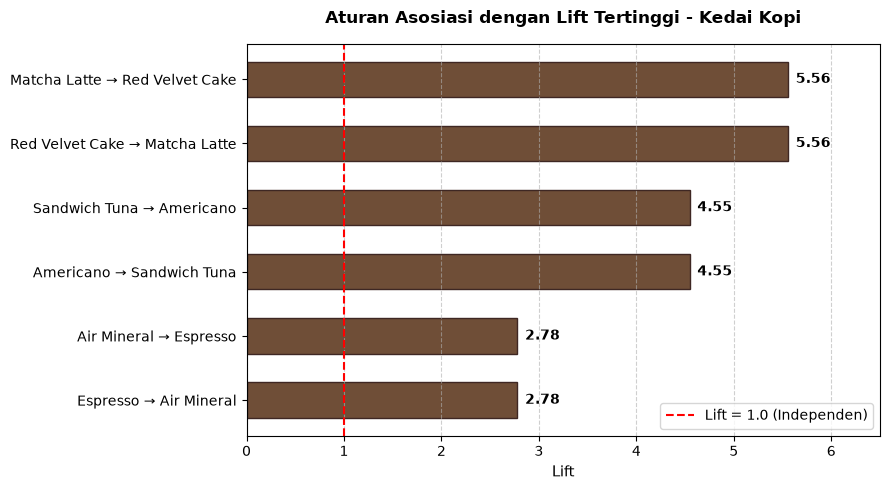

In [5]:
# Visualisasi Bar Chart Lift Tertinggi - Kedai Kopi
top_cs = rules_cs.head(6).copy()
labels_cs = [f"{', '.join(list(a))} → {', '.join(list(c))}" for a, c in zip(top_cs['antecedents'], top_cs['consequents'])]
labels_cs.reverse()
lifts_cs = list(top_cs['lift'])
lifts_cs.reverse()

plt.figure(figsize=(9, 5))
bars = plt.barh(labels_cs, lifts_cs, color='#6F4E37', edgecolor='#3E2723', height=0.55)
plt.axvline(x=1.0, color='red', linestyle='--', linewidth=1.5, label='Lift = 1.0 (Independen)')
plt.title('Aturan Asosiasi dengan Lift Tertinggi - Kedai Kopi', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Lift', fontsize=11)
plt.xlim(0, 6.5)
for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 0.08, bar.get_y() + bar.get_height()/2.0, f'{xval:.2f}', ha='left', va='center', fontsize=10, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### 4.3 Rekomendasi Bisnis Konkret Kedai Kopi
1. **Paket "Sweet Matcha Break" (Matcha Latte + Red Velvet Cake)**:
   - *Dasar Data*: $Lift = 5.56, Confidence = 88.9\%$. Pola ini merupakan korelasi paling kuat pada kedai.
   - *Aksi*: Menjual paket bundling hemat sore hari (jam 14.00–17.00) dengan diskon 15% untuk menarik segmen mahasiswa/pekerja non-kopi.
2. **Paket "Executive Quick Lunch" (Americano + Sandwich Tuna)**:
   - *Dasar Data*: $Lift = 4.55, Confidence = 90.9\%$. Pasangan menu makan siang cepat saji.
   - *Aksi*: Kasir dilatih melakukan *upselling* proaktif ("Tambah Sandwich Tuna hanya Rp15.000 setiap pembelian Americano") dan menyajikannya secara cepat untuk pekerja kantor.
3. **Standar Penyajian Espresso + Air Mineral & Penempatan Pastry Display**:
   - *Dasar Data*: $Lift = 2.78, Confidence = 100\%$ ($\{\text{Espresso}\} \rightarrow \{\text{Air Mineral}\}$) serta $Lift = 2.14, Confidence = 94.1\%$ ($\{\text{Kopi Susu Aren}\} \rightarrow \{\text{Croissant Butter}\}$).
   - *Aksi*: Menyediakan complimentary segelas air mineral kecil secara *built-in* pada sajian espresso (meningkatkan kepuasan pelanggan), serta meletakkan display etalase Croissant tepat di depan antrean pemesanan Kopi Susu Aren untuk memaksimalkan *impulse buying*.
